# Step 0 : Install & download models

In [2]:
!pip install mediapipe


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.5/36.5 MB 20.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.4/137.4 kB 5.5 MB/s eta 0:00:00
  Attempting uninstall: absl-py
    Found existing installation: absl-py 1.4.0
    Uninstalling absl-py-1.4.0:
      Successfully uninstalled absl-py-1.4.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.


In [5]:
import os
import urllib.request
import cv2
import numpy as np
import mediapipe as mp

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

BaseOptions = python.BaseOptions

In [4]:
MODEL_DIR = "/kaggle/working/mp_models"
os.makedirs(MODEL_DIR, exist_ok=True)

POSE_URL = "https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_lite/float16/latest/pose_landmarker_lite.task"
HAND_URL = "https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/latest/hand_landmarker.task"

pose_model_path = os.path.join(MODEL_DIR, "pose_landmarker.task")
hand_model_path = os.path.join(MODEL_DIR, "hand_landmarker.task")
if not os.path.exists(pose_model_path):
    urllib.request.urlretrieve(POSE_URL, pose_model_path)
if not os.path.exists(hand_model_path):
    urllib.request.urlretrieve(HAND_URL, hand_model_path)

print("Models ready:", os.path.exists(pose_model_path), os.path.exists(hand_model_path))

Models ready: True True


# Step  1: Load Dataset

In [6]:
!git clone https://github.com/AI4Bharat/OpenHands.git
%cd OpenHands

Cloning into 'OpenHands'...
remote: Enumerating objects: 2057, done.
remote: Counting objects: 100% (121/121), done.
remote: Compressing objects: 100% (40/40), done.
remote: Total 2057 (delta 101), reused 81 (delta 81), pack-reused 1936 (from 3)
Receiving objects: 100% (2057/2057), 6.08 MiB | 11.82 MiB/s, done.
Resolving deltas: 100% (1249/1249), done.
/kaggle/working/OpenHands


In [7]:
from openhands.datasets.isolated import INCLUDEDataset

print("INCLUDEDataset imported successfully")

/kaggle/working/OpenHands/openhands/datasets/isolated/devisign.py:26: SyntaxWarning: invalid escape sequence '\`'
  Check the file "DEVISIGN Technical Report.pdf" inside `Documents\` folder


INCLUDEDataset imported successfully


In [8]:
%cd /kaggle/working

!wget -O INCLUDE.zip \
"https://zenodo.org/record/6674324/files/INCLUDE.zip?download=1"

/kaggle/working
--2026-08-11 03:04:24--  https://zenodo.org/record/6674324/files/INCLUDE.zip?download=1
Resolving zenodo.org (zenodo.org)... 137.138.153.219, 137.138.52.235, 188.184.103.118, ...
Connecting to zenodo.org (zenodo.org)|137.138.153.219|:443... connected.
HTTP request sent, awaiting response... 301 MOVED PERMANENTLY
Location: /records/6674324/files/INCLUDE.zip [following]
--2026-08-11 03:04:24--  https://zenodo.org/records/6674324/files/INCLUDE.zip
Reusing existing connection to zenodo.org:443.
HTTP request sent, awaiting response... 200 OK
Length: 662887244 (632M) [application/octet-stream]
Saving to: ‘INCLUDE.zip’

INCLUDE.zip         100%[===================>] 632.18M  25.6MB/s    in 23s     

2026-08-11 03:04:47 (27.5 MB/s) - ‘INCLUDE.zip’ saved [662887244/662887244]



In [9]:
!mkdir -p /kaggle/working/INCLUDE

In [10]:
!unzip -q /kaggle/working/INCLUDE.zip \
    -d /kaggle/working/INCLUDE

In [11]:

for root, dirs, files in os.walk("/kaggle/working/INCLUDE/INCLUDE"):
    print(root)
    print("Files:", files[:10])

    if root.count(os.sep) > 5:
        dirs[:] = []


/kaggle/working/INCLUDE/INCLUDE
Files: ['Pose_Signs.zip', 'Train_Test_Split.zip']


In [22]:
# DATASET_DIR = "/kaggle/working/INCLUDE/INCLUDE/Pose_Signs/Pose_Signs"

# import os

# for root, dirs, files in os.walk(DATASET_DIR):
#     print(root, "→", len(files), "files")
#     if files:
#         print("   ", files[:5])

In [23]:
!find /kaggle/working/INCLUDE -maxdepth 3 -type f | head -50

/kaggle/working/INCLUDE/INCLUDE/Pose_Signs.zip
/kaggle/working/INCLUDE/INCLUDE/Train_Test_Split.zip


# Step 2 : Unzip and inspect the split file

In [25]:
import zipfile

base = "/kaggle/working/INCLUDE/INCLUDE"
for z in ["Pose_Signs.zip", "Train_Test_Split.zip"]:
    zp = os.path.join(base, z)
    out = os.path.join(base, z.replace(".zip", ""))
    if not os.path.exists(out):
        with zipfile.ZipFile(zp) as f:
            f.extractall(out)
    print("Extracted:", out)

Extracted: /kaggle/working/INCLUDE/INCLUDE/Pose_Signs
Extracted: /kaggle/working/INCLUDE/INCLUDE/Train_Test_Split


In [27]:
# DATA_ROOT = "/kaggle/working/INCLUDE/INCLUDE/Pose_Signs"

# for root, dirs, files in os.walk(DATA_ROOT):
#     depth = root.replace(DATA_ROOT, "").count(os.sep)
#     print("  " * depth + os.path.basename(root) + "/")
#     for f in files[:5]:
#         print("  " * (depth + 1) + f)
#     if depth > 3:  # stop going deeper once we've seen enough
#         dirs[:] = []

In [28]:
import pickle, glob

DATA_ROOT = "/kaggle/working/INCLUDE/INCLUDE/Pose_Signs/Pose_Signs"


#  Confirm folder structure 
categories = sorted([d for d in os.listdir(DATA_ROOT) if os.path.isdir(os.path.join(DATA_ROOT, d))])
print(f"Total categories: {len(categories)}")
print("Categories:", categories)

class_dirs = []  # category, sign_name, full_path
for category in categories:
    category_path = os.path.join(DATA_ROOT, category)
    for sign_name in sorted(os.listdir(category_path)):
        sign_path = os.path.join(category_path, sign_name)
        if os.path.isdir(sign_path):
            class_dirs.append((category, sign_name, sign_path))

print(f"\nTotal sign classes: {len(class_dirs)}")

sign_names = [name for _, name, _ in class_dirs]
print("Unique sign names:", len(set(sign_names)))
if len(sign_names) != len(set(sign_names)):
    print("Sign names repeat across categories — labels must use category+sign_name combined")
else:
    print(" Sign names are globally unique — sign_name alone is safe as the label")


Total categories: 15
Categories: ['Adjectives', 'Animals', 'Clothes', 'Colours', 'Days_and_Time', 'Electronics', 'Greetings', 'Home', 'Jobs', 'Means_of_Transportation', 'People', 'Places', 'Pronouns', 'Seasons', 'Society']

Total sign classes: 263
Unique sign names: 263
 Sign names are globally unique — sign_name alone is safe as the label


In [29]:
# 2. Find and inspect one sample .pkl file automatically 
all_pkls = glob.glob(os.path.join(DATA_ROOT, "**", "*.pkl"), recursive=True)
print(f"\nTotal .pkl files found: {len(all_pkls)}")

if all_pkls:
    sample_path = all_pkls[0]
    print("Inspecting sample:", sample_path)

    with open(sample_path, "rb") as f:
        data = pickle.load(f)

    print("\nType:", type(data))

    if isinstance(data, dict):
        print("Keys:", list(data.keys()))
        for k, v in data.items():
            shape = getattr(v, "shape", None)
            length = len(v) if hasattr(v, "__len__") else None
            print(f"  {k}: type={type(v)}, shape={shape}, len={length}")
            if shape is None and length and length > 0:
                print(f"    first element: {v[0]}")

    elif hasattr(data, "shape"):
        print("Array shape:", data.shape)
        print("dtype:", data.dtype)
        print("Sample values:", data.flatten()[:10])

    elif isinstance(data, list):
        print("List length:", len(data))
        print("First element type:", type(data[0]))
        print("First element:", data[0])

    else:
        print("Raw value preview:", data)
else:
    print(" No .pkl files found — double check DATA_ROOT path matches your extracted structure")


Total .pkl files found: 4284
Inspecting sample: /kaggle/working/INCLUDE/INCLUDE/Pose_Signs/Pose_Signs/Jobs/97. Reporter/MVI_4512.pkl

Type: <class 'dict'>
Keys: ['keypoints', 'confidences', 'vid_shape']
  keypoints: type=<class 'numpy.ndarray'>, shape=(83, 75, 3), len=83
  confidences: type=<class 'numpy.ndarray'>, shape=(83, 75), len=83
  vid_shape: type=<class 'tuple'>, shape=None, len=2
    first element: 1080


In [30]:
 # 3. Count videos (pkl files) per class, to check class balance 
counts = []
for category, sign_name, sign_path in class_dirs:
    n = len([f for f in os.listdir(sign_path) if f.endswith(".pkl")])
    counts.append(n)

import numpy as np
counts = np.array(counts)
print(f"\nSamples per class — min: {counts.min()}, max: {counts.max()}, mean: {counts.mean():.1f}")


Samples per class — min: 0, max: 22, mean: 16.2


In [31]:
# Quick sanity check on value range

import pickle, numpy as np

sample_path = "/kaggle/working/INCLUDE/INCLUDE/Pose_Signs/Pose_Signs/Society/5. Bill/MVI_4269.pkl"
with open(sample_path, "rb") as f:
    data = pickle.load(f)

kp = data["keypoints"]
conf = data["confidences"]
print("vid_shape:", data["vid_shape"])
print("keypoints min/max per axis:", kp[..., 0].min(), kp[..., 0].max(), "|",
      kp[..., 1].min(), kp[..., 1].max(), "|", kp[..., 2].min(), kp[..., 2].max())
print("confidences min/max/mean:", conf.min(), conf.max(), conf.mean())

vid_shape: (1080, 1920)
keypoints min/max per axis: 0.0 694.9155306816101 | 0.0 2568.311233520508 | -0.7178532481193542 0.3914903700351715
confidences min/max/mean: 0.0 1.0 0.8404035235496685


In [32]:
DATA_ROOT = "/kaggle/working/INCLUDE/INCLUDE/Pose_Signs/Pose_Signs"
OUT_DIR = "/kaggle/working/landmarks"
os.makedirs(OUT_DIR, exist_ok=True)

MAX_FRAMES = 40

# Build class list, skipping empty folders
class_dirs = []
for category in sorted(os.listdir(DATA_ROOT)):
    category_path = os.path.join(DATA_ROOT, category)
    if not os.path.isdir(category_path):
        continue
    for sign_name in sorted(os.listdir(category_path)):
        sign_path = os.path.join(category_path, sign_name)
        if not os.path.isdir(sign_path):
            continue
        n_pkls = len([f for f in os.listdir(sign_path) if f.endswith(".pkl")])
        if n_pkls > 0:
            class_dirs.append((sign_name, sign_path))

class_names = sorted(set(name for name, _ in class_dirs))
class_to_idx = {name: i for i, name in enumerate(class_names)}
print(f"Usable classes (non-empty): {len(class_names)} (dropped {263 - len(class_names)} empty)")

def load_pkl_sequence(pkl_path, max_frames=MAX_FRAMES):
    with open(pkl_path, "rb") as f:
        d = pickle.load(f)
    kp = d["keypoints"].astype(np.float32)  # (frames, 75, 3)
    h, w = d["vid_shape"][:2]

    # Normalize if values look like pixel coordinates
    if kp[..., 0].max() > 5:  # heuristic: normalized coords should be roughly 0-1
        kp[..., 0] /= w
        kp[..., 1] /= h
        # z left as-is (relative depth, no consistent pixel scale to divide by)

    seq = kp.reshape(kp.shape[0], -1)  # (frames, 225)

    if len(seq) < max_frames:
        pad = np.zeros((max_frames - len(seq), seq.shape[1]), dtype=np.float32)
        seq = np.vstack([seq, pad])
    return seq[:max_frames]

X_list, y_list = [], []
for sign_name, sign_path in class_dirs:
    pkls = [f for f in os.listdir(sign_path) if f.endswith(".pkl")]
    for pkl_file in pkls:
        seq = load_pkl_sequence(os.path.join(sign_path, pkl_file))
        X_list.append(seq)
        y_list.append(class_to_idx[sign_name])

X = np.array(X_list, dtype=np.float32)
y = np.array(y_list, dtype=np.int64)

np.save(os.path.join(OUT_DIR, "X.npy"), X)
np.save(os.path.join(OUT_DIR, "y.npy"), y)
np.save(os.path.join(OUT_DIR, "class_names.npy"), np.array(class_names))

print("Final shapes:", X.shape, y.shape, "| classes:", len(class_names))

Usable classes (non-empty): 262 (dropped 1 empty)
Final shapes: (4257, 40, 225) (4257,) | classes: 262


In [33]:
# the sanity check to confirm the confidence-cleanup :
X = np.load("/kaggle/working/landmarks/X.npy")
y = np.load("/kaggle/working/landmarks/y.npy")

print("Any NaN or Inf?", np.isnan(X).any(), np.isinf(X).any())
print("Value range:", X.min(), X.max())
print("Fraction of zeroed (low-confidence/padding) values:", (X == 0).mean())

# Class balance check
unique, counts = np.unique(y, return_counts=True)
print(f"\nSamples per class — min: {counts.min()}, max: {counts.max()}, mean: {counts.mean():.1f}")
print("Classes with fewer than 5 samples:", (counts < 5).sum())

Any NaN or Inf? False False
Value range: -1.1471734 2.8704967
Fraction of zeroed (low-confidence/padding) values: 0.11321517500587268

Samples per class — min: 4, max: 22, mean: 16.2
Classes with fewer than 5 samples: 2


# Step 3: Stratified train/val split

In [34]:
import numpy as np
import torch
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader

X = np.load("/kaggle/working/landmarks/X.npy")
y = np.load("/kaggle/working/landmarks/y.npy")
class_names = np.load("/kaggle/working/landmarks/class_names.npy")
NUM_CLASSES = len(class_names)

train_idx, val_idx = train_test_split(
    np.arange(len(y)),
    test_size=0.15,
    stratify=y,
    random_state=42
)

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]

print("Train:", X_train.shape, "Val:", X_val.shape)

class SignDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
    def __len__(self): return len(self.X)
    def __getitem__(self, i): return self.X[i], self.y[i]

train_ds = SignDataset(X_train, y_train)
val_ds = SignDataset(X_val, y_val)
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=32)

Train: (3618, 40, 225) Val: (639, 40, 225)


# Step 4 Transformer model

In [37]:
import torch.nn as nn, math

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=100):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1).float()
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))
    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

class SignTransformer(nn.Module):
    def __init__(self, input_dim=225, d_model=256, nhead=8, num_layers=4,
                 num_classes=NUM_CLASSES, max_len=MAX_FRAMES, dropout=0.2):
        super().__init__()
        self.input_proj = nn.Linear(input_dim, d_model)
        self.pos_encoder = PositionalEncoding(d_model, max_len + 1)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=d_model * 4,
            dropout=dropout, batch_first=True, activation="gelu"
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.cls_token = nn.Parameter(torch.randn(1, 1, d_model))
        self.classifier = nn.Sequential(
            nn.LayerNorm(d_model),
            nn.Linear(d_model, 128), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(128, num_classes)
        )
    def forward(self, x):
        x = self.input_proj(x)
        cls = self.cls_token.expand(x.size(0), -1, -1)
        x = torch.cat([cls, x], dim=1)
        x = self.pos_encoder(x)
        x = self.transformer(x)
        return self.classifier(x[:, 0, :])

# Step 5: Traing The Model

In [38]:
device = "cuda" if torch.cuda.is_available() else "cpu"
model = SignTransformer(num_classes=NUM_CLASSES, max_len=MAX_FRAMES).to(device)
opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=100)

EPOCHS = 100
best_val = 0

for epoch in range(EPOCHS):
    model.train()
    correct, total, train_loss = 0, 0, 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad()
        out = model(xb)
        loss = criterion(out, yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        opt.step()
        train_loss += loss.item()
        correct += (out.argmax(1) == yb).sum().item()
        total += yb.size(0)
    scheduler.step()

    model.eval()
    v_correct, v_total = 0, 0
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            v_correct += (out.argmax(1) == yb).sum().item()
            v_total += yb.size(0)
    val_acc = v_correct / v_total

    if val_acc > best_val:
        best_val = val_acc
        torch.save(model.state_dict(), "/kaggle/working/sign_transformer_best.pt")

    if epoch % 5 == 0 or epoch == EPOCHS - 1:
        print(f"Epoch {epoch}: loss={train_loss/len(train_loader):.4f} "
              f"train_acc={correct/total:.3f} val_acc={val_acc:.3f} (best={best_val:.3f})")

print("Training done. Best val accuracy:", best_val)

Epoch 0: loss=5.5819 train_acc=0.005 val_acc=0.003 (best=0.003)
Epoch 5: loss=5.1172 train_acc=0.011 val_acc=0.014 (best=0.014)
Epoch 10: loss=4.7937 train_acc=0.025 val_acc=0.030 (best=0.030)
Epoch 15: loss=4.3480 train_acc=0.072 val_acc=0.077 (best=0.100)
Epoch 20: loss=3.7570 train_acc=0.173 val_acc=0.186 (best=0.186)
Epoch 25: loss=3.2360 train_acc=0.310 val_acc=0.268 (best=0.272)
Epoch 30: loss=2.7965 train_acc=0.433 val_acc=0.382 (best=0.382)
Epoch 35: loss=2.3935 train_acc=0.567 val_acc=0.459 (best=0.459)
Epoch 40: loss=2.0821 train_acc=0.679 val_acc=0.540 (best=0.540)
Epoch 45: loss=1.8263 train_acc=0.769 val_acc=0.603 (best=0.623)
Epoch 50: loss=1.6177 train_acc=0.834 val_acc=0.662 (best=0.662)
Epoch 55: loss=1.4672 train_acc=0.888 val_acc=0.695 (best=0.695)
Epoch 60: loss=1.3633 train_acc=0.927 val_acc=0.696 (best=0.700)
Epoch 65: loss=1.2775 train_acc=0.955 val_acc=0.725 (best=0.725)
Epoch 70: loss=1.2184 train_acc=0.976 val_acc=0.739 (best=0.746)
Epoch 75: loss=1.1860 train

# Step 6: MODEL EVALUATION

In [39]:
model.load_state_dict(torch.load("/kaggle/working/sign_transformer_best.pt", map_location=device))
model.eval()

all_preds, all_labels, all_confs = [], [], []
with torch.no_grad():
    for xb, yb in val_loader:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        probs = torch.softmax(out, dim=1)
        conf, pred = probs.max(dim=1)
        all_preds.extend(pred.cpu().numpy())
        all_labels.extend(yb.cpu().numpy())
        all_confs.extend(conf.cpu().numpy())

all_preds, all_labels, all_confs = np.array(all_preds), np.array(all_labels), np.array(all_confs)
val_acc = (all_preds == all_labels).mean()
print(f"Validation accuracy: {val_acc:.4f}")

Validation accuracy: 0.7700


In [40]:
from sklearn.metrics import classification_report
import pandas as pd

report = classification_report(all_labels, all_preds, target_names=class_names, zero_division=0, output_dict=True)
df = pd.DataFrame(report).T.iloc[:-3].sort_values("f1-score")

print("Worst 15 classes:")
print(df.head(15)[["precision", "recall", "f1-score", "support"]])
print("\nBest 10 classes:")
print(df.tail(10)[["precision", "recall", "f1-score", "support"]])

def topk_accuracy(model, loader, k):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            topk = out.topk(k, dim=1).indices
            correct += sum(yb[i] in topk[i] for i in range(len(yb)))
            total += yb.size(0)
    return correct / total

for k in [1, 3, 5]:
    print(f"Top-{k} accuracy: {topk_accuracy(model, val_loader, k):.4f}")

Worst 15 classes:
              precision    recall  f1-score  support
99. Job        0.000000  0.000000  0.000000      2.0
84. Evening    0.000000  0.000000  0.000000      2.0
30. Bedroom    0.000000  0.000000  0.000000      2.0
77. Boy        0.000000  0.000000  0.000000      3.0
4. Bird        0.000000  0.000000  0.000000      3.0
42. he         0.000000  0.000000  0.000000      3.0
43. she        0.000000  0.000000  0.000000      3.0
38. Dress      0.000000  0.000000  0.000000      3.0
67. Monday     0.000000  0.000000  0.000000      2.0
51. Clock      0.000000  0.000000  0.000000      2.0
59. Daughter   0.000000  0.000000  0.000000      3.0
46. Clothing   0.250000  0.333333  0.285714      3.0
58. Son        0.250000  0.333333  0.285714      3.0
71. Husband    0.250000  0.333333  0.285714      3.0
64. Man        0.333333  0.333333  0.333333      3.0

Best 10 classes:
               precision  recall  f1-score  support
2. Cat               1.0     1.0       1.0      3.0
19. male    

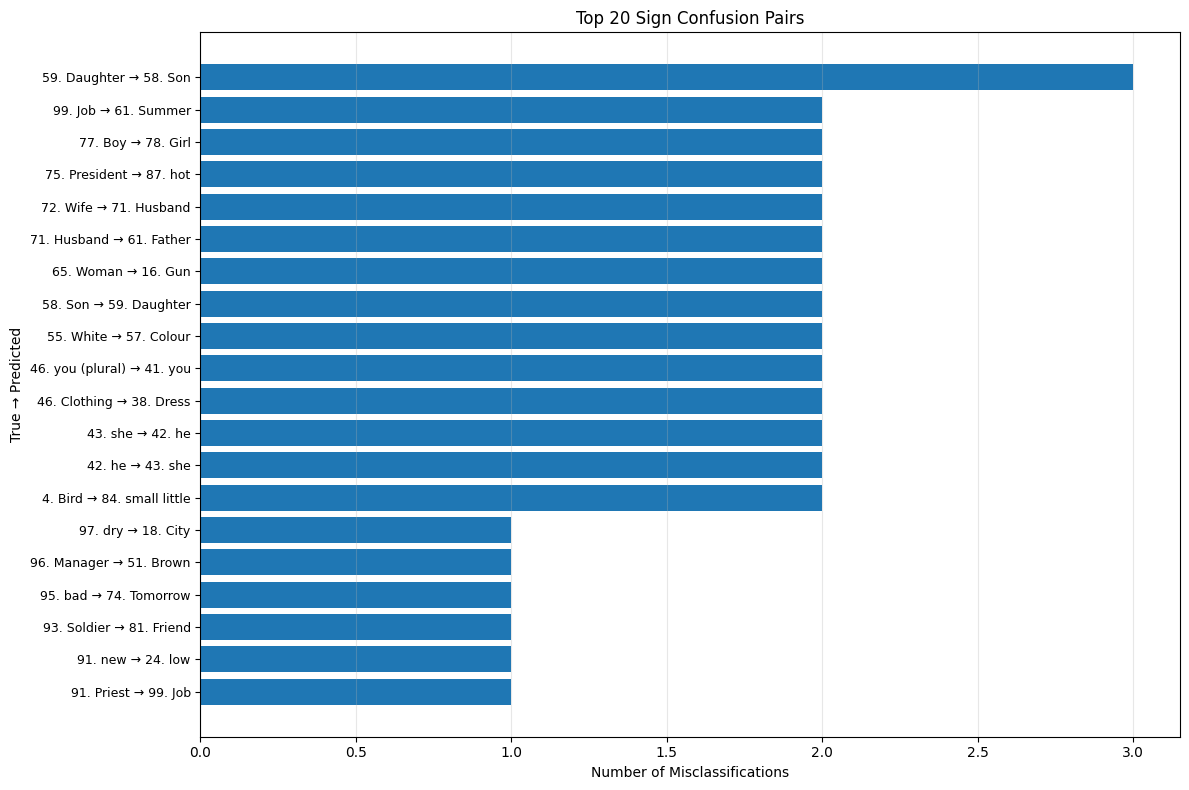

In [56]:
cm_no_self = cm.copy()
np.fill_diagonal(cm_no_self, 0)

pairs = []

for true_idx in range(NUM_CLASSES):
    for pred_idx in range(NUM_CLASSES):

        count = cm_no_self[true_idx, pred_idx]

        if count > 0:
            pairs.append(
                (
                    count,
                    true_idx,
                    pred_idx
                )
            )

pairs.sort(reverse=True)

top_n = 20
top_pairs = pairs[:top_n]

labels = [
    f"{class_names[t]} → {class_names[p]}"
    for count, t, p in top_pairs
]

values = [
    count
    for count, t, p in top_pairs
]

plt.figure(figsize=(12, 8))

plt.barh(
    range(top_n),
    values
)

plt.yticks(
    range(top_n),
    labels,
    fontsize=9
)

plt.xlabel("Number of Misclassifications")
plt.ylabel("True → Predicted")
plt.title("Top 20 Sign Confusion Pairs")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig("/kaggle/working/confusion_matrix.png", dpi=150)
plt.show()

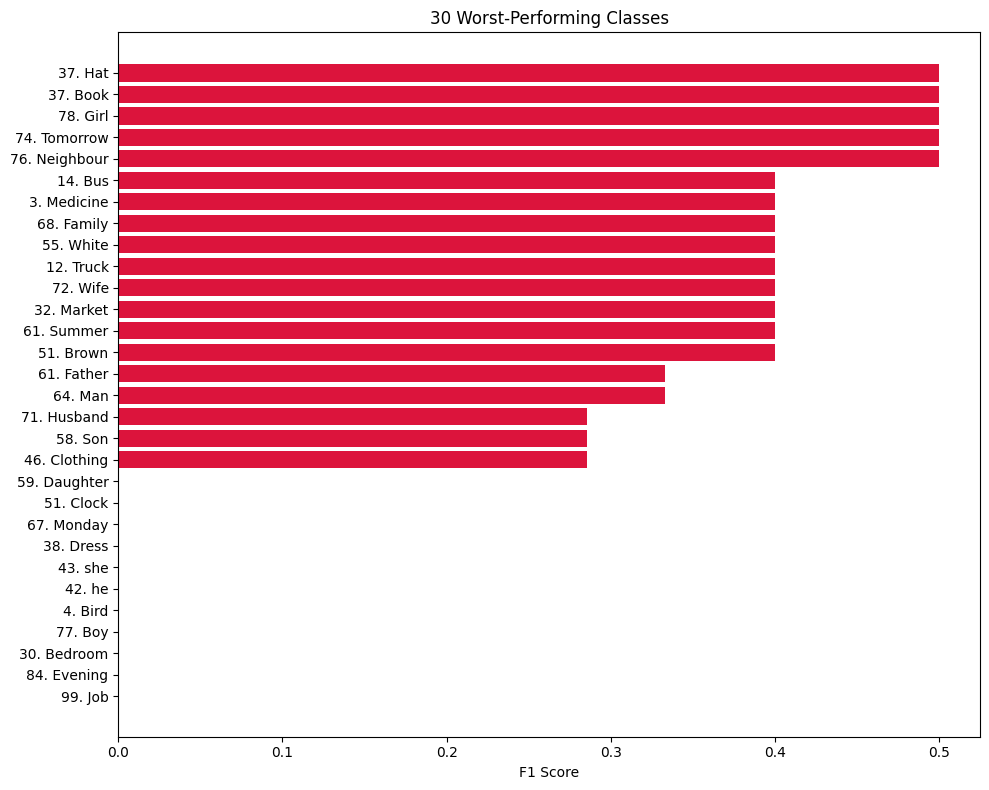

In [48]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import seaborn as sns

plt.figure(figsize=(10, 8))
worst30 = df.head(30)
plt.barh(worst30.index, worst30["f1-score"], color="crimson")
plt.xlabel("F1 Score")
plt.title("30 Worst-Performing Classes")
plt.tight_layout()
plt.savefig("/kaggle/working/worst_classes_f1.png", dpi=150)
plt.show()

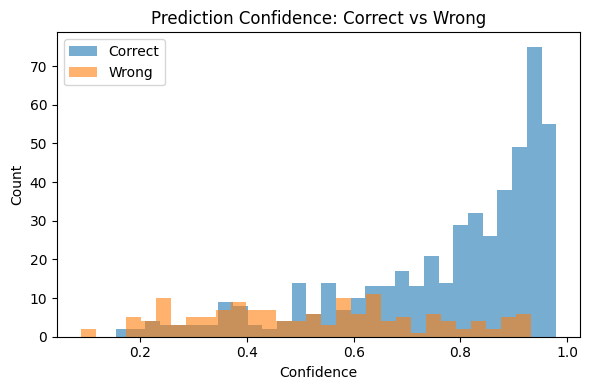

In [57]:
# Confidence: correct vs wrong 
plt.figure(figsize=(6, 4))
plt.hist(all_confs[all_preds == all_labels], bins=30, alpha=0.6, label="Correct")
plt.hist(all_confs[all_preds != all_labels], bins=30, alpha=0.6, label="Wrong")
plt.xlabel("Confidence"); plt.ylabel("Count"); plt.legend()
plt.title("Prediction Confidence: Correct vs Wrong")
plt.tight_layout()
# plt.savefig("/kaggle/working/confidence_dist.png", dpi=150)
plt.show()

In [45]:
# Remove correct predictions
cm_noself = cm.copy()
np.fill_diagonal(cm_noself, 0)

# Get strongest confusion pairs
pairs = []

for true_idx in range(NUM_CLASSES):
    for pred_idx in range(NUM_CLASSES):
        count = cm_noself[true_idx, pred_idx]

        if count > 0:
            pairs.append(
                (
                    count,
                    class_names[true_idx],
                    class_names[pred_idx]
                )
            )

# sort number of mistakes
pairs = sorted(
    pairs,
    key=lambda x: x[0],
    reverse=True
)

print("\nTop 30 Confused Class Pairs")
print("=" * 60)

for count, true_class, predicted_class in pairs[:30]:
    print(
        f"True: {str(true_class):20s} "
        f"→ Predicted: {str(predicted_class):20s} "
        f"| Errors: {count}"
    )


Top 30 Confused Class Pairs
True: 59. Daughter         → Predicted: 58. Son              | Errors: 3
True: 4. Bird              → Predicted: 84. small little     | Errors: 2
True: 42. he               → Predicted: 43. she              | Errors: 2
True: 43. she              → Predicted: 42. he               | Errors: 2
True: 46. Clothing         → Predicted: 38. Dress            | Errors: 2
True: 46. you (plural)     → Predicted: 41. you              | Errors: 2
True: 55. White            → Predicted: 57. Colour           | Errors: 2
True: 58. Son              → Predicted: 59. Daughter         | Errors: 2
True: 65. Woman            → Predicted: 16. Gun              | Errors: 2
True: 71. Husband          → Predicted: 61. Father           | Errors: 2
True: 72. Wife             → Predicted: 71. Husband          | Errors: 2
True: 75. President        → Predicted: 87. hot              | Errors: 2
True: 77. Boy              → Predicted: 78. Girl             | Errors: 2
True: 99. Job         

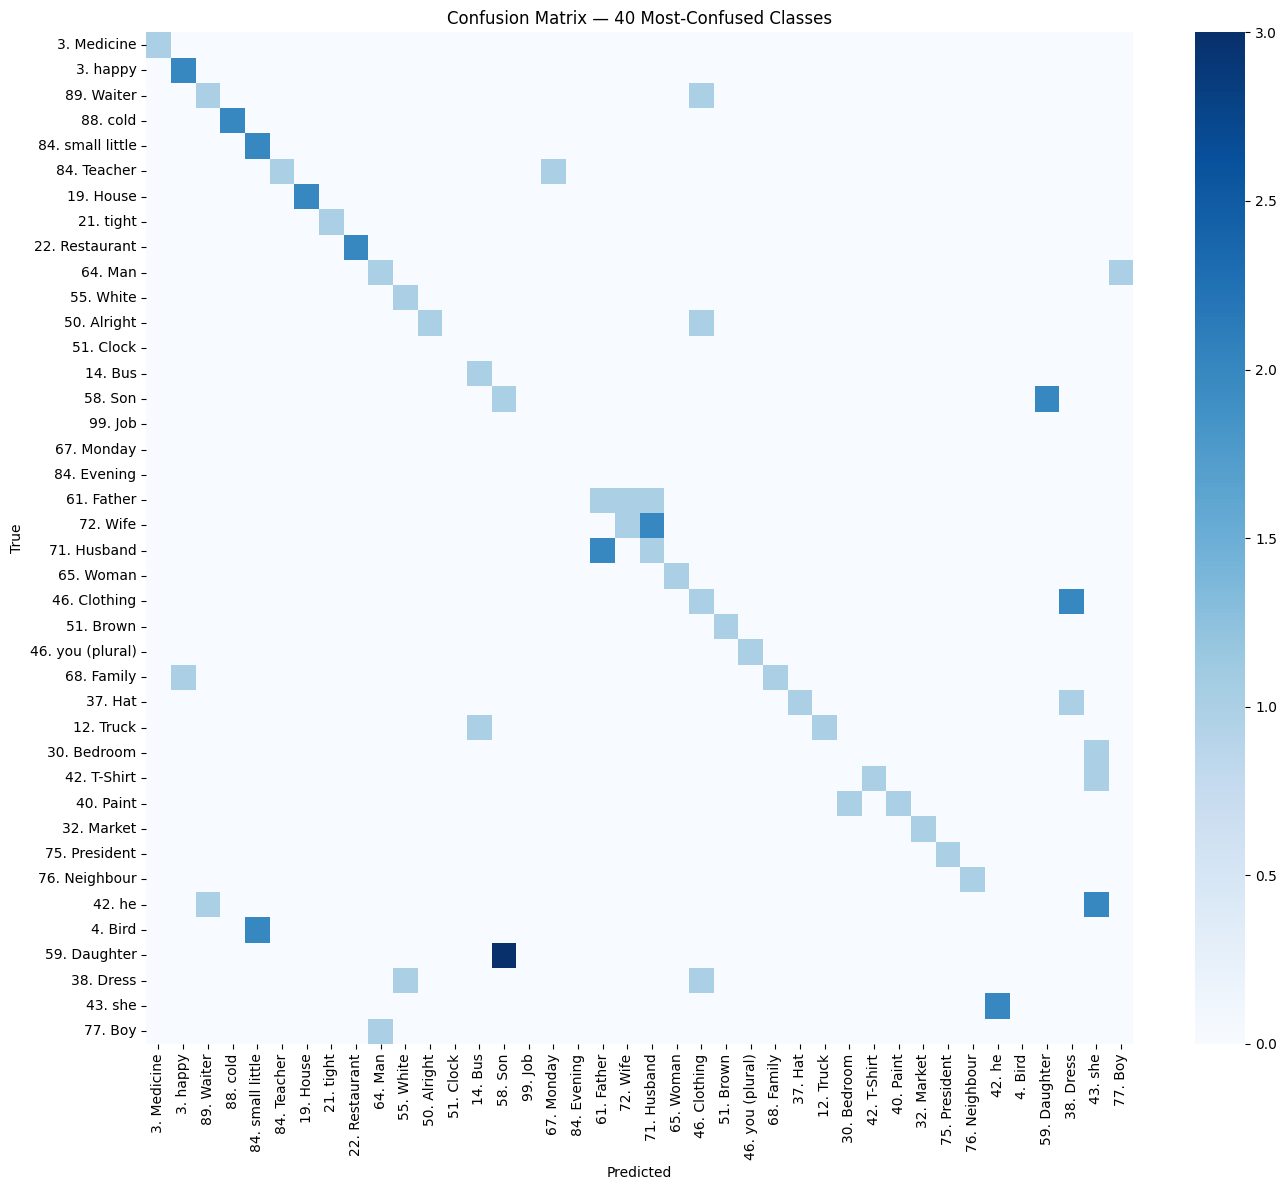

In [58]:
cm = confusion_matrix(all_labels, all_preds, labels=range(NUM_CLASSES))
cm_noself = cm.copy()
np.fill_diagonal(cm_noself, 0)
top_confused_idx = np.argsort(cm_noself.sum(axis=1))[-40:]

plt.figure(figsize=(14, 12))
sns.heatmap(cm[np.ix_(top_confused_idx, top_confused_idx)],
            xticklabels=class_names[top_confused_idx],
            yticklabels=class_names[top_confused_idx],
            cmap="Blues", annot=False)
plt.xlabel("Predicted"); plt.ylabel("True")
plt.title("Confusion Matrix — 40 Most-Confused Classes")
plt.xticks(rotation=90); plt.yticks(rotation=0)
plt.tight_layout()
# plt.savefig("/kaggle/working/confusion_matrix.png", dpi=150)
plt.show()

# save

In [42]:
import json

save_bundle = {
    "model_state_dict": model.state_dict(),
    "class_names": class_names.tolist(),
    "config": {
        "input_dim": 225,
        "d_model": 256,
        "nhead": 8,
        "num_layers": 4,
        "num_classes": NUM_CLASSES,
        "max_len": MAX_FRAMES,
        "dropout": 0.2
    }
}
torch.save(save_bundle, "/kaggle/working/sign_model_full.pt")
print("Saved bundle:", os.path.getsize("/kaggle/working/sign_model_full.pt") / 1e6, "MB")

Saved bundle: 13.206261 MB
